# Bài 25 - Experiment 6: Pooling strategy

So sánh **masked mean pooling** và **CLS-style first-token pooling** trong cùng một Transformer classifier cho IMDb. Hai mô hình dùng chung dữ liệu, split, tokenizer, encoder, kích thước embedding, batch size, optimizer, learning rate và số epoch. Token `cls` được thêm ở đầu mỗi review để first-token pooling có một vị trí chuyên biệt có thể học sequence representation.

In [ ]:
import os, random, tarfile, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
def reset_seed():
    os.environ['PYTHONHASHSEED'] = str(SEED)
    random.seed(SEED)
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)

reset_seed()
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


## 1. Tải và chuẩn bị IMDb

Thử tải ACL IMDb từ Stanford; nếu nguồn đó không kết nối được thì dùng bản IMDb của Keras/TensorFlow. Tách validation từ train có stratify; giữ test set đến bước đánh giá cuối.

In [ ]:
DATA_DIR = Path('/content/aclImdb')
ARCHIVE = Path('/content/aclImdb_v1.tar.gz')
DATA_URL = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'

if not (DATA_DIR / 'train' / 'pos').exists():
    try:
        if not ARCHIVE.exists():
            print('Đang tải ACL IMDb từ Stanford (~84 MB)...')
            urllib.request.urlretrieve(DATA_URL, ARCHIVE)
        with tarfile.open(ARCHIVE, 'r:gz') as archive:
            archive.extractall('/content', filter='data')
    except Exception as err:
        ARCHIVE.unlink(missing_ok=True)
        print('Không tải được Stanford:', repr(err))

        try:
            print('Đang thử bản IMDb qua Keras/TensorFlow...')
            (x_train_raw, y_train_raw), (x_test_raw, y_test) = tf.keras.datasets.imdb.load_data(seed=SEED)
            word_index = tf.keras.datasets.imdb.get_word_index()
            reverse_index = {i + 3: word for word, i in word_index.items()}

            def decode_review(sequence):
                return ' '.join(reverse_index.get(int(i), '<UNK>') for i in sequence if int(i) > 3)

            all_train_texts = [decode_review(s) for s in x_train_raw]
            all_train_labels = np.asarray(y_train_raw, dtype=np.int32)
            test_texts = [decode_review(s) for s in x_test_raw]
            y_test = np.asarray(y_test, dtype=np.int32)
        except Exception as fallback_err:
            raise RuntimeError('IMDb không tải được từ Stanford hoặc Keras. Kiểm tra Internet rồi chạy lại.') from fallback_err

if 'all_train_texts' not in globals():
    def read_split(split):
        texts, labels = [], []
        for folder, label in [('neg', 0), ('pos', 1)]:
            for path in sorted((DATA_DIR / split / folder).glob('*.txt')):
                texts.append(path.read_text(encoding='utf-8', errors='replace').strip())
                labels.append(label)
        return texts, np.asarray(labels, dtype=np.int32)

    all_train_texts, all_train_labels = read_split('train')
    test_texts, y_test = read_split('test')

train_texts, val_texts, y_train, y_val = train_test_split(
    all_train_texts, all_train_labels, test_size=0.1, random_state=SEED, stratify=all_train_labels
)
print(f'Train: {len(train_texts):,} | Validation: {len(val_texts):,} | Test: {len(test_texts):,}')
print('Train labels [negative, positive]:', np.bincount(y_train))

Đang tải ACL IMDb từ Stanford (~84 MB)...
Không tải được Stanford: URLError(ConnectionRefusedError(111, 'Connection refused'))
Đang thử bản IMDb qua Keras/TensorFlow...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 22,500 | Validation: 2,500 | Test: 25,000
Train labels [negative, positive]: [11250 11250]


## 2. Một tokenizer và cùng input cho cả hai mô hình

Thêm chuỗi `cls` vào đầu mọi review trước khi fit tokenizer. Vì `cls` ở vị trí 0 và không bị cắt khi truncation ở cuối, CLS-style pooling luôn đọc đúng vector token đầu tiên. Cả hai cách pooling nhận cùng các token IDs và padding mask.

In [ ]:
MAX_VOCAB = 20000
MAX_LEN = 128
EMBED_DIM = 64
NUM_HEADS = 4
FF_DIM = 128
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 1e-3
CLS_TOKEN = 'cls'

def add_cls(texts):
    return [f'{CLS_TOKEN} {text}' for text in texts]

train_with_cls = add_cls(train_texts)
val_with_cls = add_cls(val_texts)
test_with_cls = add_cls(test_texts)
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(train_with_cls)
vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
cls_id = tokenizer.word_index[CLS_TOKEN]

def encode(texts):
    sequences = tokenizer.texts_to_sequences(texts)
    ids = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post', value=0)
    return ids, sequences

X_train, train_sequences = encode(train_with_cls)
X_val, val_sequences = encode(val_with_cls)
X_test, test_sequences = encode(test_with_cls)
print('Vocabulary size:', vocab_size, '| CLS token ID:', cls_id)
print('Shapes:', X_train.shape, X_val.shape, X_test.shape)
print('First token IDs (sample):', X_train[0, :8])
print('CLS is at position 0:', bool(np.all(X_train[:, 0] == cls_id)))

Vocabulary size: 20000 | CLS token ID: 30
Shapes: (22500, 128) (2500, 128) (25000, 128)
First token IDs (sample): [  30   59  195  146   22    2 1126    5]
CLS is at position 0: True


## 3. Chung một Transformer Encoder, thay đổi pooling

Masked mean lấy trung bình các token hợp lệ. CLS-style pooling lấy vector ở vị trí 0; token `cls` tham gia self-attention và có thể tổng hợp thông tin từ review. Chỉ phép gộp sequence representation khác nhau giữa hai mô hình.

In [ ]:
class SinusoidalPositionEncoding(layers.Layer):
    def call(self, x):
        length, dim = tf.shape(x)[1], tf.shape(x)[2]
        positions = tf.cast(tf.range(length)[:, None], tf.float32)
        indices = tf.cast(tf.range(dim)[None, :], tf.float32)
        rates = tf.pow(10000.0, -(2.0 * tf.floor(indices / 2.0)) / tf.cast(dim, tf.float32))
        angles = positions * rates
        even = tf.equal(tf.math.floormod(tf.range(dim), 2), 0)[None, :]
        encoding = tf.where(even, tf.sin(angles), tf.cos(angles))[None, :, :]
        return x + tf.cast(encoding, x.dtype)

class TransformerEncoderBlock(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=EMBED_DIM // NUM_HEADS, dropout=0.1)
        self.ffn = models.Sequential([layers.Dense(FF_DIM, activation='relu'), layers.Dense(EMBED_DIM)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(0.1)
        self.drop2 = layers.Dropout(0.1)

    def call(self, inputs, training=None):
        x, valid_tokens = inputs
        key_mask = valid_tokens[:, None, :]
        attended = self.attention(query=x, value=x, key=x, attention_mask=key_mask, training=training)
        x = self.norm1(x + self.drop1(attended, training=training))
        transformed = self.ffn(x, training=training)
        return self.norm2(x + self.drop2(transformed, training=training))

class MaskedMeanPooling(layers.Layer):
    def call(self, inputs):
        sequence, valid_tokens = inputs
        mask = tf.cast(valid_tokens[:, :, None], sequence.dtype)
        total = tf.reduce_sum(sequence * mask, axis=1)
        count = tf.maximum(tf.reduce_sum(mask, axis=1), tf.ones_like(tf.reduce_sum(mask, axis=1)))
        return total / count

class FirstTokenPooling(layers.Layer):
    def call(self, sequence):
        return sequence[:, 0, :]

def build_classifier(pooling):
    token_ids = layers.Input(shape=(MAX_LEN,), dtype='int32', name='token_ids')
    valid_tokens = layers.Lambda(lambda ids: tf.not_equal(ids, 0), name='valid_tokens')(token_ids)
    x = layers.Embedding(vocab_size, EMBED_DIM, name='embedding')(token_ids)
    x = SinusoidalPositionEncoding(name='positional_encoding')(x)
    x = TransformerEncoderBlock(name='transformer_encoder')([x, valid_tokens])
    if pooling == 'mean':
        x = MaskedMeanPooling(name='masked_mean_pooling')([x, valid_tokens])
    elif pooling == 'cls':
        x = FirstTokenPooling(name='first_token_pooling')(x)
    else:
        raise ValueError("pooling must be 'mean' or 'cls'")
    x = layers.Dropout(0.1)(x)
    probability = layers.Dense(1, activation='sigmoid', name='positive_probability')(x)
    model = models.Model(token_ids, probability, name=f'IMDb_Transformer_{pooling}_pooling')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

mean_model = build_classifier('mean')
mean_parameters = mean_model.count_params()
mean_model.summary()

Model: "IMDb_Transformer_mean_pooling"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 128, 64)   │  1,280,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 128, 64)   │          0 │ embedding[0][0]   │
│ (SinusoidalPositio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ valid_tokens        │ (None, 128)       │          0 │ token_ids[0][0]   │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encoder │ (None, 128, 64)   │     33,472 │ positional_encod… │
│ (TransformerEncode… │                   │            │ valid_tokens[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masked_mean_pooling │ (None, 64)        │          0 │ transformer_enco… │
│ (MaskedMeanPooling) │                   │            │ valid_tokens[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ masked_mean_pool… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positive_probabili… │ (None, 1)         │         65 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,313,537 (5.01 MB)

 Trainable params: 1,313,537 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện với cùng cấu hình

Reset seed trước mỗi lần khởi tạo để giảm khác biệt do khởi tạo ngẫu nhiên. Thời gian phụ thuộc runtime Colab; hai mô hình được huấn luyện nối tiếp trên cùng runtime.

In [ ]:
def fit_one(pooling_name):
    reset_seed()
    model = build_classifier(pooling_name)
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=2
    )
    seconds = time.perf_counter() - start
    return model, history, seconds

mean_model, mean_history, mean_seconds = fit_one('mean')
cls_model, cls_history, cls_seconds = fit_one('cls')
print(f'Mean pooling training time: {mean_seconds:.1f} seconds')
print(f'CLS-style pooling training time: {cls_seconds:.1f} seconds')

Epoch 1/3
352/352 - 112s - 319ms/step - accuracy: 0.7155 - loss: 0.5235 - val_accuracy: 0.8376 - val_loss: 0.3572
Epoch 2/3
352/352 - 106s - 303ms/step - accuracy: 0.8809 - loss: 0.2896 - val_accuracy: 0.8528 - val_loss: 0.3576
Epoch 3/3
352/352 - 142s - 403ms/step - accuracy: 0.9223 - loss: 0.1974 - val_accuracy: 0.8360 - val_loss: 0.4435
Epoch 1/3
352/352 - 110s - 312ms/step - accuracy: 0.6735 - loss: 0.5599 - val_accuracy: 0.8296 - val_loss: 0.3674
Epoch 2/3
352/352 - 106s - 301ms/step - accuracy: 0.8719 - loss: 0.3033 - val_accuracy: 0.8476 - val_loss: 0.3723
Epoch 3/3
352/352 - 109s - 310ms/step - accuracy: 0.9182 - loss: 0.2113 - val_accuracy: 0.8420 - val_loss: 0.4499
Mean pooling training time: 396.4 seconds
CLS-style pooling training time: 324.8 seconds


## 5. Đánh giá trên test set

Báo cáo accuracy, precision, recall, F1, số tham số và training time cho mỗi pooling strategy.

In [ ]:
def evaluate_model(name, model, seconds):
    probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(np.int32)
    return {
        'Pooling': name,
        'Parameters': model.count_params(),
        'Training time (s)': round(seconds, 2),
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
    }, predictions

mean_result, mean_predictions = evaluate_model('Masked mean', mean_model, mean_seconds)
cls_result, cls_predictions = evaluate_model('CLS-style first token', cls_model, cls_seconds)
results = pd.DataFrame([mean_result, cls_result])
display(results.round({'Accuracy': 4, 'Precision': 4, 'Recall': 4, 'F1': 4}))
print('Confusion matrix - masked mean [negative, positive]:\n', confusion_matrix(y_test, mean_predictions))
print('Confusion matrix - CLS-style [negative, positive]:\n', confusion_matrix(y_test, cls_predictions))

,Pooling,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,Masked mean,1313537,396.38,0.8059,0.8524,0.7399,0.7922
1,CLS-style first token,1313537,324.76,0.8109,0.8588,0.7442,0.7974


Confusion matrix - masked mean [negative, positive]:
 [[10899  1601]
 [ 3251  9249]]
Confusion matrix - CLS-style [negative, positive]:
 [[10970  1530]
 [ 3198  9302]]


## 6. Learning curves

Xem train/validation accuracy và loss theo epoch cho hai chiến lược pooling.

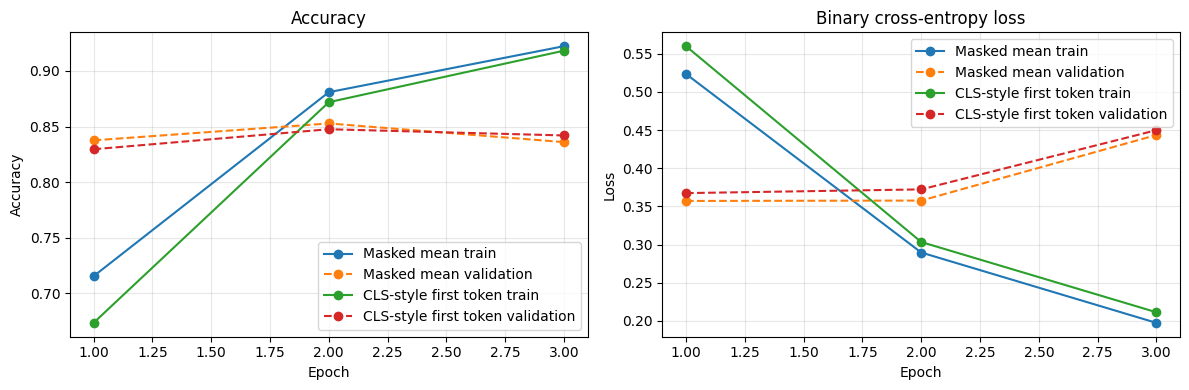

In [ ]:
histories = {'Masked mean': mean_history.history, 'CLS-style first token': cls_history.history}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, history in histories.items():
    epochs = range(1, len(history['accuracy']) + 1)
    axes[0].plot(epochs, history['accuracy'], marker='o', label=f'{label} train')
    axes[0].plot(epochs, history['val_accuracy'], marker='o', linestyle='--', label=f'{label} validation')
    axes[1].plot(epochs, history['loss'], marker='o', label=f'{label} train')
    axes[1].plot(epochs, history['val_loss'], marker='o', linestyle='--', label=f'{label} validation')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[1].set_title('Binary cross-entropy loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()